# 4 · Vision SFT
**Idea:** the same as previous methods, but each example is a picture.

- circle = shirt · square = shoes · triangle = jacket
- red = RD · blue = BL · black = BK · white = WH

(a picture of a red circle) → `FIND shirt color=RD`

The model cannot guess this: the meaning of each shape is the shop's own rule.

## Step 1 · Load a small model that can read pictures

In [2]:
import warnings, random, torch
from transformers import AutoModelForImageTextToText, AutoProcessor

warnings.filterwarnings('ignore')            # hide technical warnings

MODEL = 'Qwen/Qwen3.5-0.8B'                  # the same small model; it can read pictures too
processor = AutoProcessor.from_pretrained(MODEL)   # prepares text and pictures for the model
model = AutoModelForImageTextToText.from_pretrained(MODEL, dtype=torch.bfloat16, device_map='cuda')

Could not reach the Hub ([WinError 10054] An existing connection was forcibly closed by the remote host). Using cached commit hash for 'Qwen/Qwen3.5-0.8B'.
Loading weights: 100%|██████████| 473/473 [00:01<00:00, 408.29it/s]


## Step 2 · Create the pictures
Code draws each tag, so the correct command is always known.
24 pictures to learn from (each kind of tag twice), and 6 new pictures to test.

In [3]:
ITEM = {'circle': 'shirt', 'square': 'shoes', 'triangle': 'jacket'}
CODE = {'red': 'RD', 'blue': 'BL', 'black': 'BK', 'white': 'WH'}

# Main definition mapping
print("Main mapping definition to image pictures")
for key, value in ITEM.items():
    print(f'key = {key} -> value = {value}')

print()
print('Color mapping')
for key, value in CODE.items():
    print(f'color = {key} -> code = {value}')

Main mapping definition to image pictures
key = circle -> value = shirt
key = square -> value = shoes
key = triangle -> value = jacket

Color mapping
color = red -> code = RD
color = blue -> code = BL
color = black -> code = BK
color = white -> code = WH


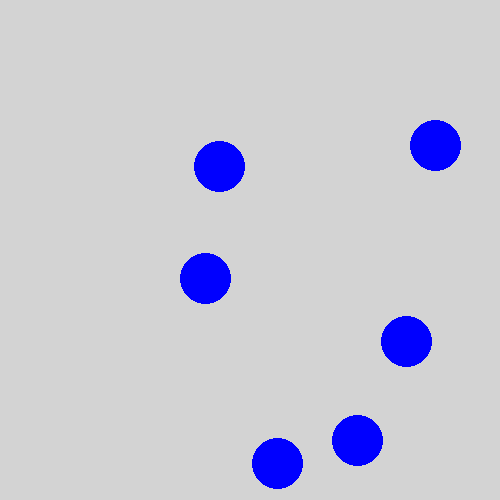

FIND shirt color=BL items=6


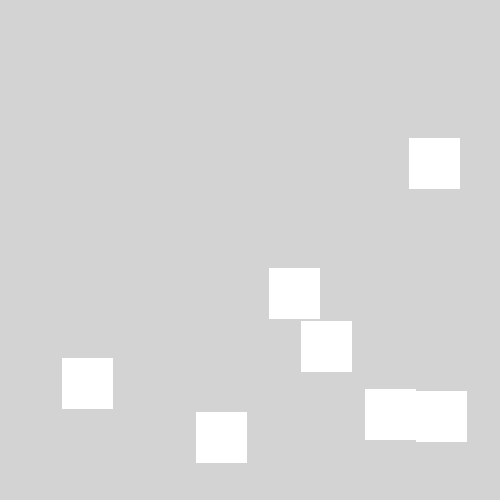

FIND shoes color=WH items=7


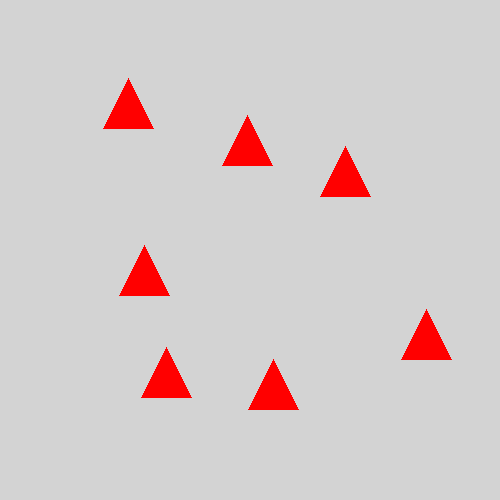

FIND jacket color=RD items=7


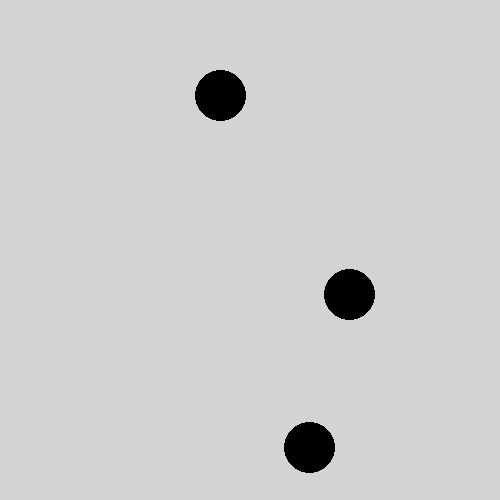

FIND shirt color=BK items=3


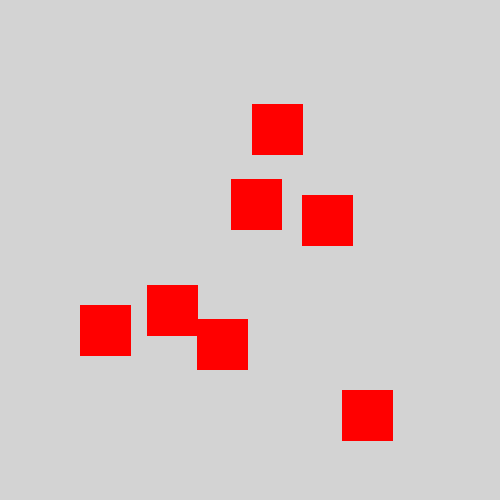

FIND shoes color=RD items=7


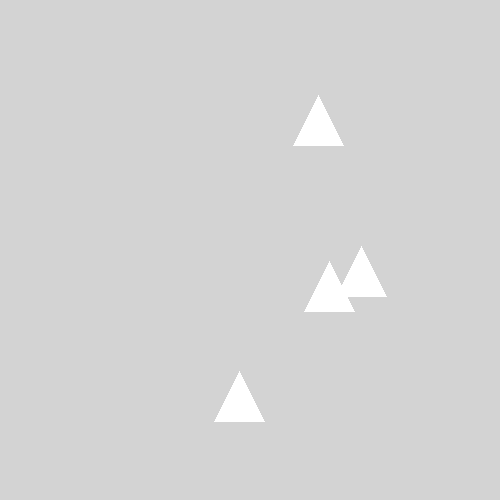

FIND jacket color=WH items=4


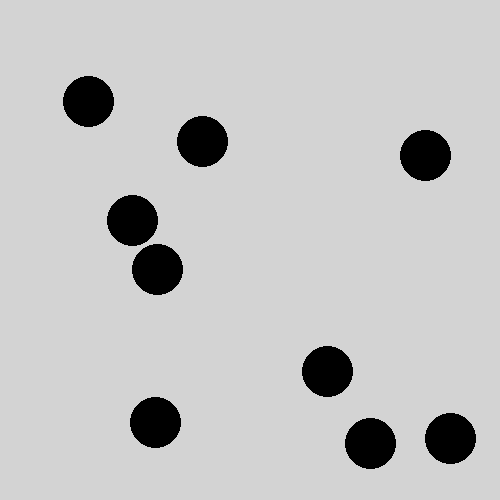

FIND shirt color=BK items=9


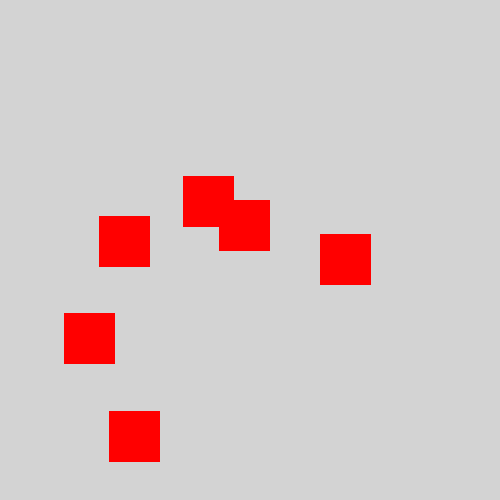

FIND shoes color=RD items=6


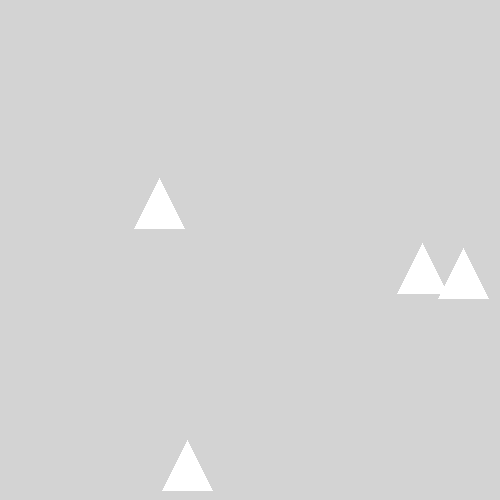

FIND jacket color=WH items=4


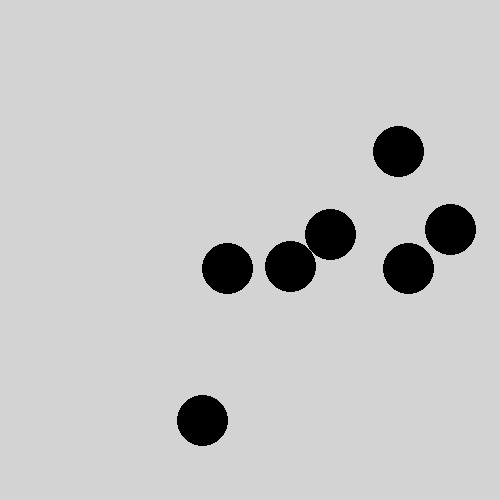

FIND shirt color=BK items=7


In [4]:
from PIL import Image, ImageDraw
import itertools

def draw(shape, color):
    # picture = Image.new('RGB', (128, 128), 'lightgray')
    picture = Image.new('RGB', (500, 500), 'lightgray')
    pen = ImageDraw.Draw(picture)

    # Generate random points and sizes for shapes
    n_items = random.randint(1,10) # random items

    # Generate specific case
    for _ in range(n_items):
        x, y = random.randint(60, 440), random.randint(60, 440)  # random place
        size = random.randint(50, 50) # random size

        if shape == 'circle':
            pen.ellipse([x, y, x + size, y + size], fill=color)

        elif shape == 'square':
            pen.rectangle([x, y, x + size, y + size], fill=color)
        else:
            pen.polygon([(x + size / 2, y), (x, y + size), (x + size, y + size)], fill=color)
    return picture, f'FIND {ITEM[shape]} color={CODE[color]} items={n_items}'

random.seed(0)
TRAIN = []
for i in range(4):
    # generate and append new list
    TRAIN.extend([draw(shape, color) for shape in ITEM for color in CODE for copy in range(2)])

TEST = [draw('circle', 'blue'), draw('square', 'white'), draw('triangle', 'red'), 
        draw('circle', 'black'), draw('square', 'red'), draw('triangle', 'white'), 
        draw('circle', 'black'), draw('square', 'red'), draw('triangle', 'white'),
        draw('circle', 'black'), draw('square', 'red'), draw('triangle', 'white')
        ]

for picture, command in TEST[:10]:
    display(picture)
    print(command)

In [5]:
len(TRAIN), len(TEST)

(96, 12)

In [6]:
TEST[:10]

[(<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND shirt color=BL items=6'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND shoes color=WH items=7'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND jacket color=RD items=7'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND shirt color=BK items=3'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND shoes color=RD items=7'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND jacket color=WH items=4'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND shirt color=BK items=9'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND shoes color=RD items=6'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND jacket color=WH items=4'),
 (<PIL.Image.Image image mode=RGB size=500x500>,
  'FIND shirt color=BK items=7')]

## Step 3 · Ask the model before training

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.



Test case: 1


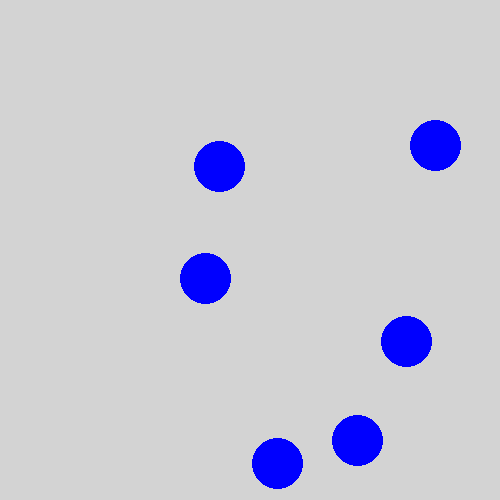

FIND shirt color=BL items=6
wrong: <points x1="416" y1="300" alt="blue circle">blue circle</points>    expected: FIND shirt color=BL items=6

Test case: 2


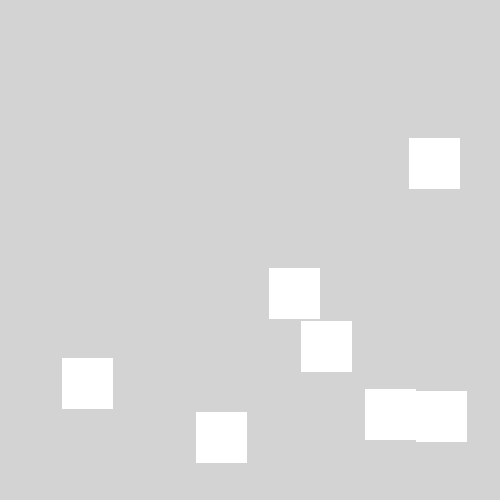

FIND shoes color=WH items=7
wrong: <template>
  <div class="box">
    <div class="box-content">
      <div class="box-icon">
        <svg class="icon" viewBox="0 0 24 24">    expected: FIND shoes color=WH items=7

Test case: 3


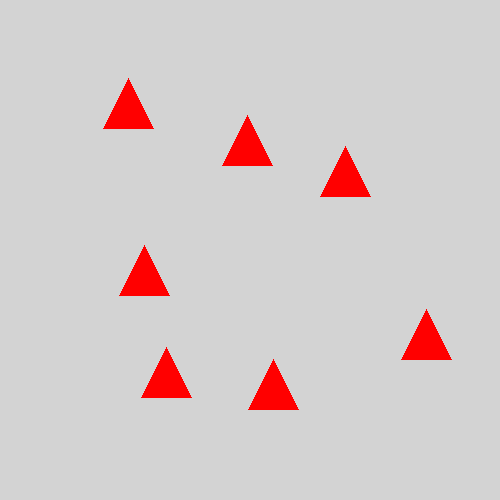

FIND jacket color=RD items=7
wrong: <points x1="137" y1="130" alt="red triangle">red triangle</points>    expected: FIND jacket color=RD items=7

Test case: 4


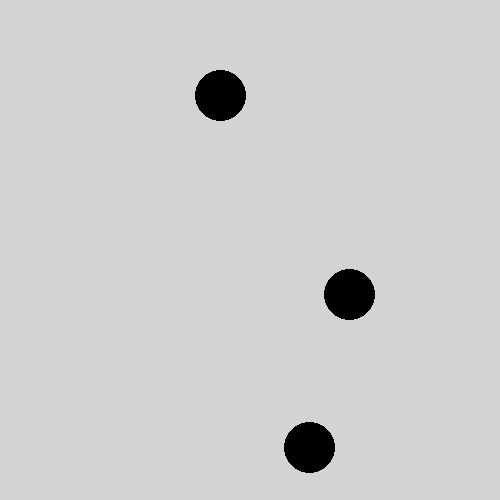

FIND shirt color=BK items=3
wrong: /    expected: FIND shirt color=BK items=3

Test case: 5


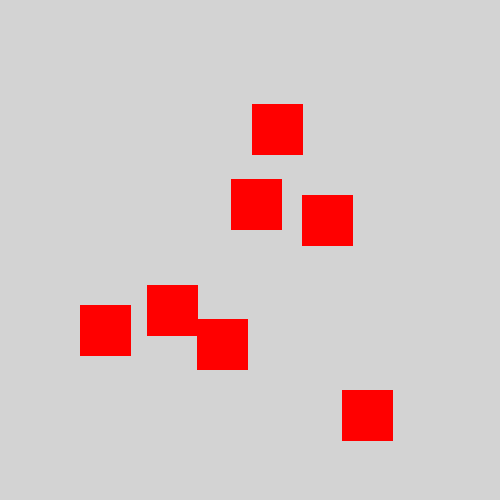

FIND shoes color=RD items=7
wrong: <svg data-bbox="0 0 999 999' data-name='1' data-name='2' data-name='3' data-name='4' data-name='5' data-name='6' data-name    expected: FIND shoes color=RD items=7

Test case: 6


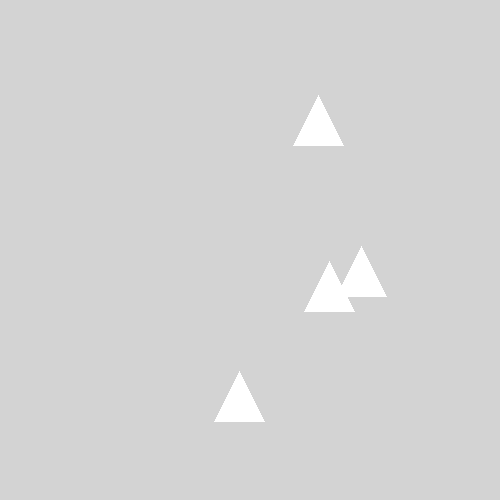

FIND jacket color=WH items=4
wrong: <image_1>    expected: FIND jacket color=WH items=4

Test case: 7


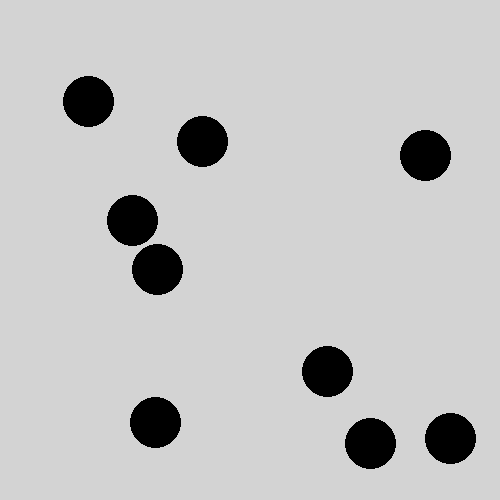

FIND shirt color=BK items=9
wrong: <points x1="139" y1="139" x2="321" y2="139" x3="469" y3="139" x4="786    expected: FIND shirt color=BK items=9

Test case: 8


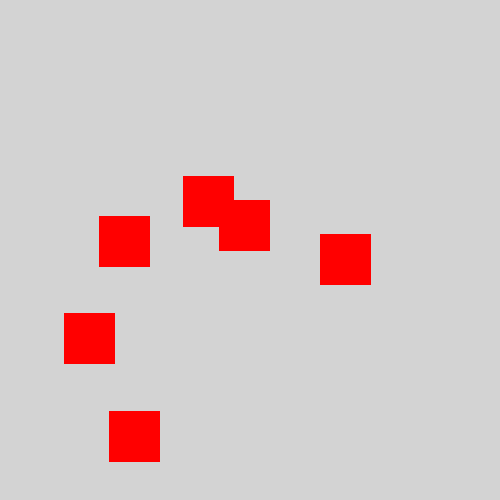

FIND shoes color=RD items=6
wrong: <svg data-bbox="0 0 999 999" data-name="Layer 1" data-cstr="1" data-name="Layer 1" data-name="Layer 1" data-name="Layer    expected: FIND shoes color=RD items=6

Test case: 9


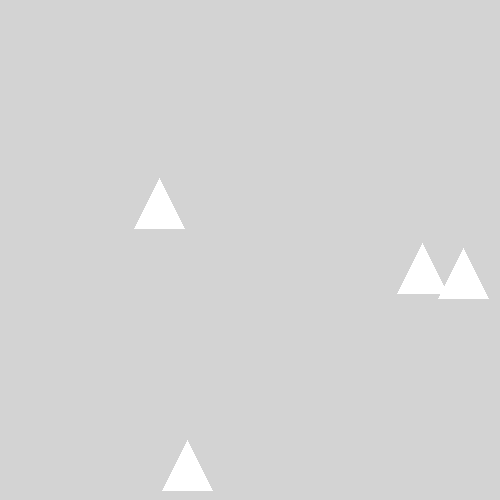

FIND jacket color=WH items=4
wrong: <image_1>    expected: FIND jacket color=WH items=4

Test case: 10


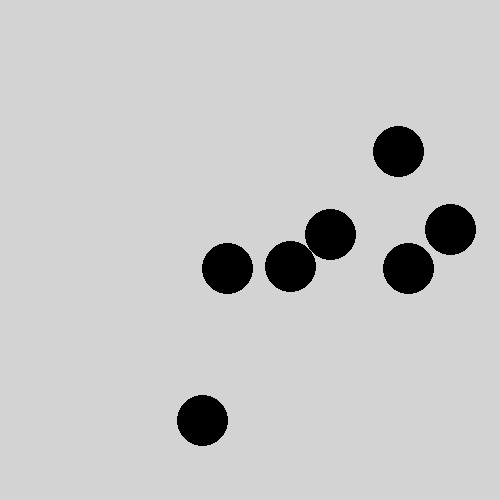

FIND shirt color=BK items=7
wrong: /label 1    expected: FIND shirt color=BK items=7

Test case: 11


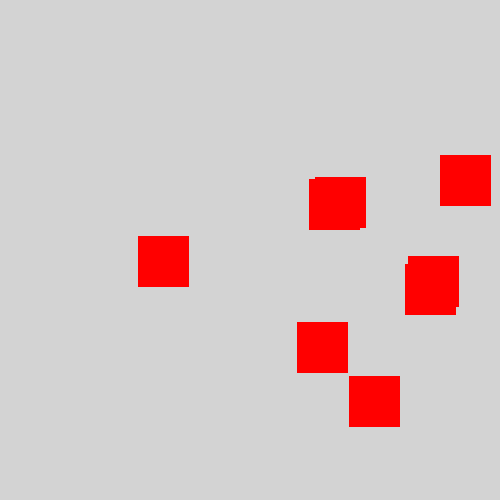

FIND shoes color=RD items=8
wrong: <svg data-bbox="0 0 999 533" data-name="Layer 1" data-cstr="1" xmlns="http://www.w3.org/2000/svg" width="99    expected: FIND shoes color=RD items=8

Test case: 12


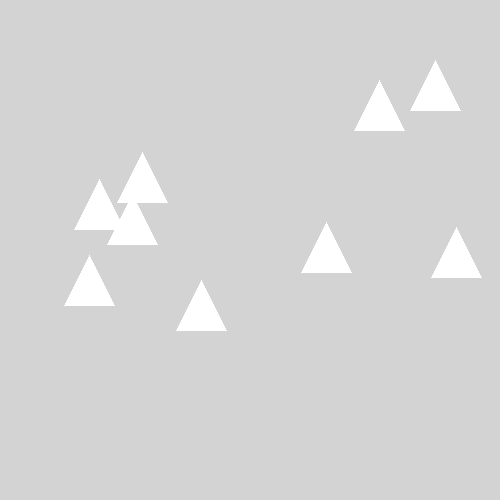

FIND jacket color=WH items=9
wrong: <svg data-bbox="0 0 999 999" height="999" width="999" viewBox="0 0 999 999" version="1.1">    expected: FIND jacket color=WH items=9
0 of 12 right


In [7]:
QUESTION = 'Search command for this tag.'

def ask(model, picture):
    chat = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': QUESTION}]}]
    text = processor.apply_chat_template(chat, add_generation_prompt=True)
    inputs = processor(text=text, images=[picture], return_tensors='pt').to('cuda', torch.bfloat16)
    output = model.generate(**inputs, max_new_tokens=50, do_sample=False)
    answer = output[0][inputs['input_ids'].shape[1]:]  # keep only the new words
    return processor.decode(answer, skip_special_tokens=True).strip()

def test(model):
    model.eval() # answering mode
    right = 0
    ii = 0 # count
    for picture, command in TEST:
        ii +=1
        answer = ask(model, picture)

        # Show the image and case to understand better
        print()
        print(f'Test case: {ii}')
        display(picture)
        print(command)

        if answer == command:
            right += 1
            print('right:', answer)
        else:
            print('wrong:', answer, '   expected:', command)
    print(right, 'of', len(TEST), 'right')

test(model)

## Step 4 · Train
The picture is turned into tokens, and then training works just like with text. Watch the `loss` go down.

In [8]:
from datasets import Dataset
from peft import LoraConfig
from trl import SFTTrainer, SFTConfig

data = Dataset.from_list([
    {'image': picture,
     'prompt': [{'role': 'user', 'content': QUESTION}],
     'completion': [{'role': 'assistant', 'content': command}]}
    for picture, command in TRAIN
])

# Train using SFT for multi modal models. This uses LORA methods to only train a small amount of layers, not all.
trainer = SFTTrainer(
    model=model,
    processing_class=processor,
    train_dataset=data,
    peft_config=LoraConfig(r=16, lora_alpha=32, target_modules='all-linear'),  # the small add-on
    args=SFTConfig(
        max_length=None, # never cut the input (it would break the picture)
        num_train_epochs=5, # each picture is seen N times (epochs)
        learning_rate=1e-4, # size of each small adjustment
        logging_steps=1, # print the loss every 3 steps
        save_strategy='no', # do not save copies to disk
    ),
)

# Apply training
trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.


Step,Training Loss
1,6.708173
2,4.880471
3,3.585075
4,2.252435
5,1.420527
6,1.016451
7,0.710649
8,0.576765
9,0.296093
10,0.291750


TrainOutput(global_step=60, training_loss=0.43353088981627175, metrics={'train_runtime': 97.6044, 'train_samples_per_second': 4.918, 'train_steps_per_second': 0.615, 'total_flos': 505460427494400.0, 'train_loss': 0.43353088981627175, 'epoch': 5.0})

## Step 5 · Ask the model after training
The same 6 test pictures. The model never saw them, so right answers mean it learned the rules.

In [9]:
# Remember mapping

# Main definition mapping
print("Main mapping definition to image pictures")
for key, value in ITEM.items():
    print(f'key = {key} -> value = {value}')
    
print()
print('Color mapping')
for key, value in CODE.items():
    print(f'color = {key} -> code = {value}')

Main mapping definition to image pictures
key = circle -> value = shirt
key = square -> value = shoes
key = triangle -> value = jacket

Color mapping
color = red -> code = RD
color = blue -> code = BL
color = black -> code = BK
color = white -> code = WH



Test case: 1


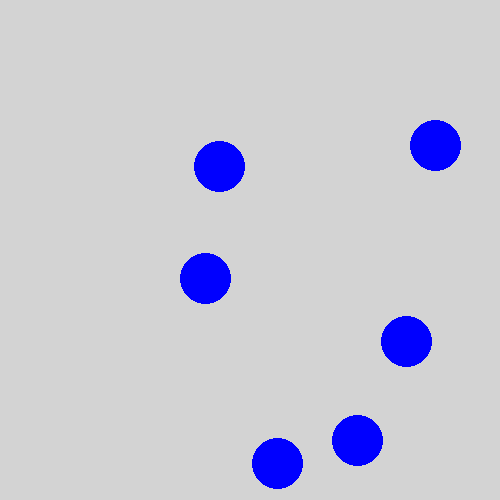

FIND shirt color=BL items=6
wrong: FIND shirt color=BL items=7    expected: FIND shirt color=BL items=6

Test case: 2


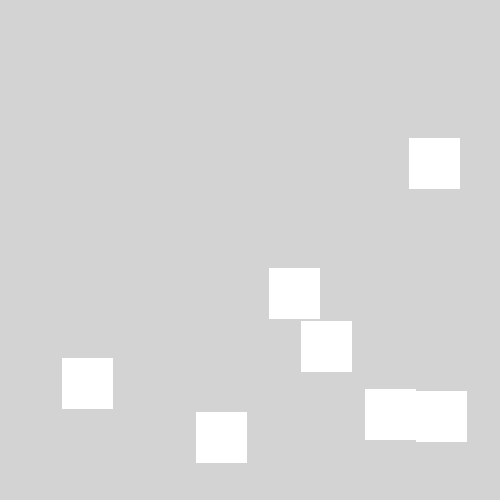

FIND shoes color=WH items=7
right: FIND shoes color=WH items=7

Test case: 3


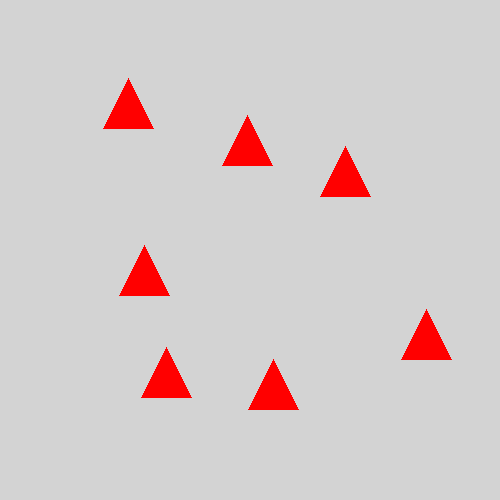

FIND jacket color=RD items=7
right: FIND jacket color=RD items=7

Test case: 4


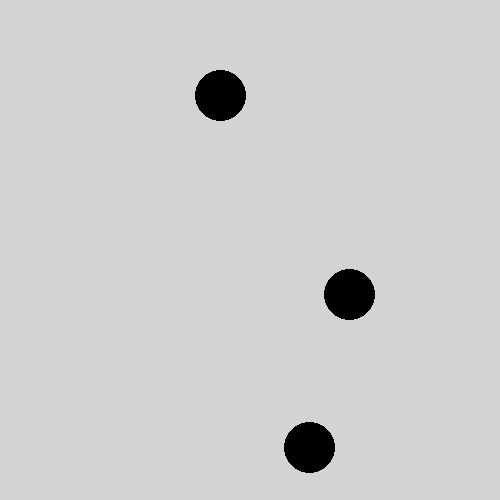

FIND shirt color=BK items=3
right: FIND shirt color=BK items=3

Test case: 5


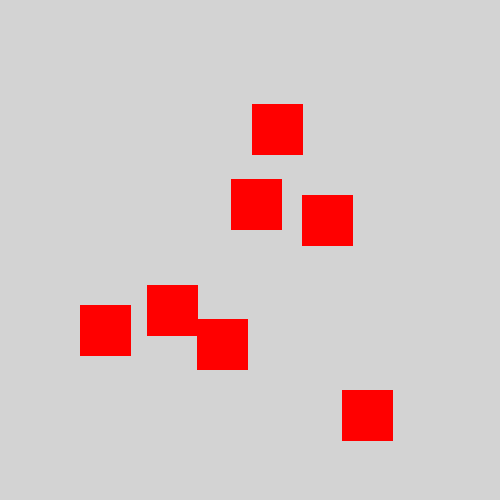

FIND shoes color=RD items=7
right: FIND shoes color=RD items=7

Test case: 6


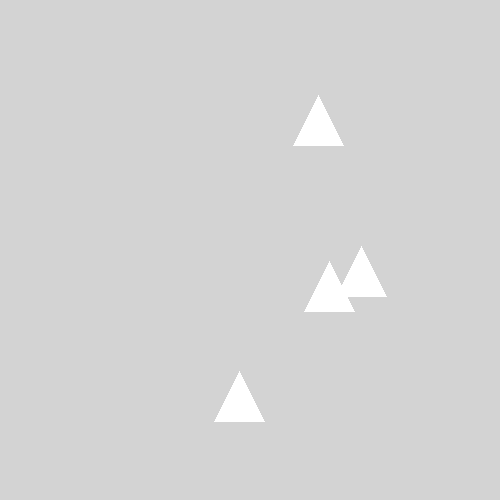

FIND jacket color=WH items=4
right: FIND jacket color=WH items=4

Test case: 7


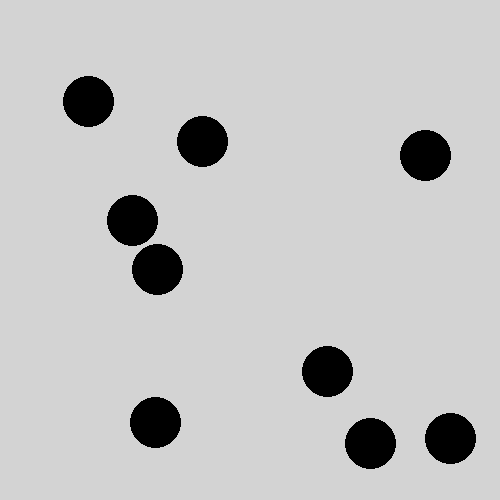

FIND shirt color=BK items=9
right: FIND shirt color=BK items=9

Test case: 8


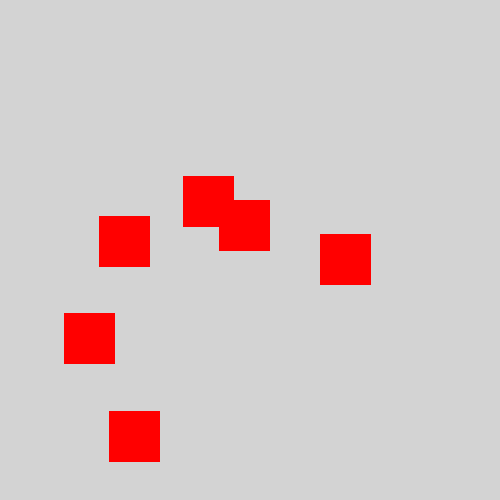

FIND shoes color=RD items=6
right: FIND shoes color=RD items=6

Test case: 9


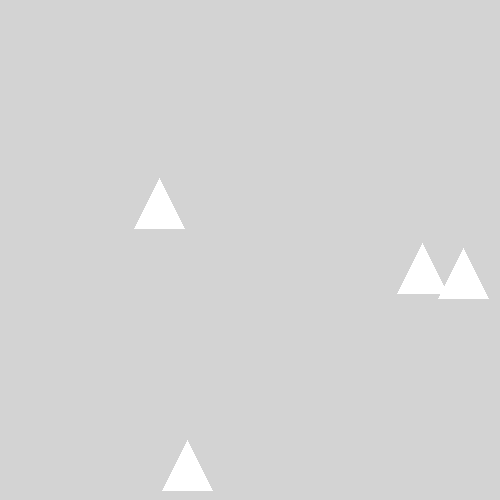

FIND jacket color=WH items=4
right: FIND jacket color=WH items=4

Test case: 10


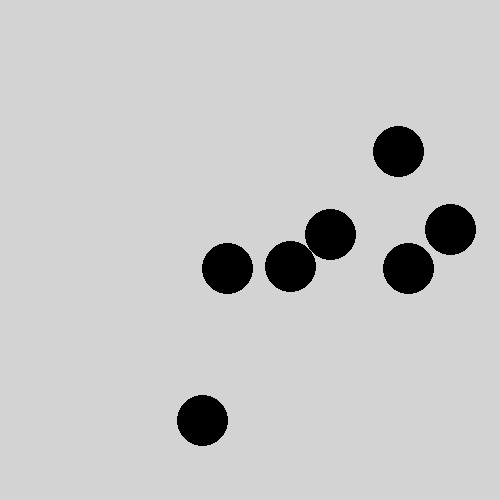

FIND shirt color=BK items=7
right: FIND shirt color=BK items=7

Test case: 11


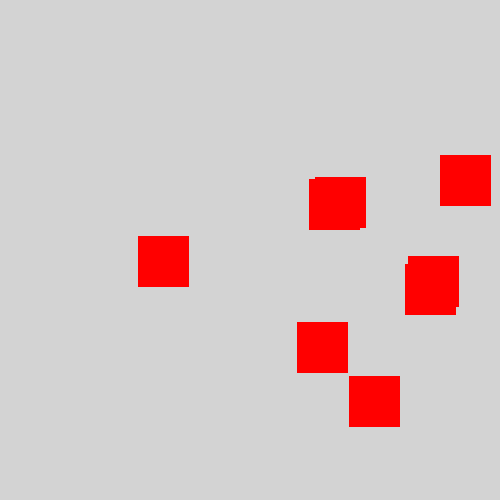

FIND shoes color=RD items=8
wrong: FIND shoes color=RD items=7    expected: FIND shoes color=RD items=8

Test case: 12


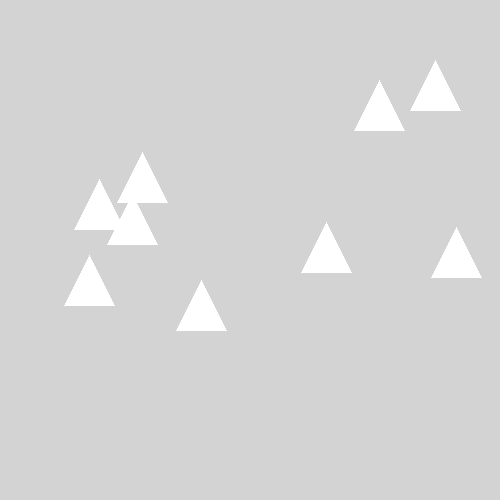

FIND jacket color=WH items=9
right: FIND jacket color=WH items=9
10 of 12 right


In [10]:
test(trainer.model)